# Ноутбук 2. Обучение модели с CCE на T4

Воспроизведение «Cut Your Losses in Large-Vocabulary Language Models» (Wijmans и др., ICLR 2025, arXiv 2411.09009v2):
сходимость дообучения (рисунок 4) и максимальный батч (рисунок 1, таблица A4).

Условия: Tesla T4, fp16 autocast, torch 2.5.1 / Triton 3.1 (отдельное окружение), Qwen2.5-0.5B-Instruct на Alpaca.
Форма блоков CCE: `b64_v64_w4`, выбранная в ноутбуке 1 (раздел 1.0).

Запуск: выполнить ячейки по порядку (на Kaggle должен быть включён Internet). Код клонируется из репозитория https://github.com/SaylesMand/Efficient-Models-HWs (папка `hw2/`), окружение ставит `hw2/scripts/setup_oldstack.sh`.
В Colab результаты и чекпоинты пишутся на Google Drive (`MyDrive/hw2_cce/results_training`): после обрыва сессии
достаточно заново выполнить ячейки, дообучение продолжится с последнего чекпоинта (каждые 100 шагов).
Без Drive (Kaggle) результаты пишутся в `results_training/` рядом с репозиторием.

В конце результаты (без чекпоинтов) упаковываются в `results_training.zip`. Результаты прогона, по которому написаны выводы ниже, лежат в репозитории в `hw2/results_training/`.

In [1]:
!nvidia-smi

Fri Oct  9 11:01:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Подготовка

In [ ]:
import os, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SaylesMand/Efficient-Models-HWs"
WORK = Path("/kaggle/working" if os.path.exists("/kaggle/working") else "/content")
REPO = WORK / "Efficient-Models-HWs"
if (REPO / ".git").exists():
    subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
HW2 = REPO / "hw2"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    RES = Path("/content/drive/MyDrive/hw2_cce/results_training")
except (ImportError, NotImplementedError):  # на Kaggle google.colab импортируется, но Drive недоступен
    # не hw2/results_training: там лежит прогон, по которому написаны выводы
    RES = WORK / "results_training"
RES.mkdir(parents=True, exist_ok=True)

os.environ["HW2"] = str(HW2)
os.environ["PYTHONPATH"] = str(HW2 / "src")
os.environ["CCE_RESULTS"] = str(RES)
os.environ["VENV"] = str(WORK / "venv_old")
PY = os.environ["PY"] = str(WORK / "venv_old" / "bin" / "python")
print("HW2 =", HW2, "| результаты:", RES)

In [3]:
!bash $HW2/scripts/setup_oldstack.sh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.8/17.8 MB 91.1 MB/s eta 0:00:00:00:0100:01
torch 2.5.1+cu121 | triton 3.1.0 | transformers 4.48.2 | Tesla T4


In [4]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def jl(exp, f="measurements.jsonl"):
    p = RES / exp / f
    if not p.exists():
        raise FileNotFoundError(f"{p}: результатов нет, см. вывод ячейки запуска и {RES / 'log.txt'}")
    return pd.read_json(p, lines=True)

## 2.1 Дообучение (рисунок 4)

**Статья.** «CCE and torch.compile have indistinguishable loss curves, demonstrating that the gradient filtering in CCE does not impair convergence (Fig. 4).» (раздел 5.3). На рисунке 4: Qwen 2.5 7B, Phi 3.5 Mini, Gemma 2 2B, Mistral NeMo на Alpaca, среднее по 5 seed.

**Что делается.** 
1. Проверка lr: torch.compile, seed 0, первые 150 шагов расписания при lr 2e-5, 7e-6 (масштабирование 64 -> 8 по корню) и 2.5e-6 (линейное). Правило, зафиксированное до прогона: из lr, при которых лосс на отложенной выборке на шаге 150 ниже, чем на шаге 0, берётся lr с наименьшим лоссом на шаге 150; полный прогон использует его автоматически, а если такого lr нет, не запускается.
2. Дообучение: полное дообучение Qwen2.5-0.5B-Instruct на Alpaca, CCE против torch.compile (контроль статьи), 3 seed, 500 шагов, батч 8 последовательностей до 512 токенов, gradient checkpointing, fp16 autocast и GradScaler. Как в [`training/train.py`](https://github.com/apple-aiml-research/ml-cross-entropy/blob/main/training/train.py) авторов (HF Trainer): формат примеров (системный промпт «You are a helpful AI assistant.» и шаблон Alpaca, в лосс идёт только ответ), AdamW, weight decay 0, прогрев 25 шагов (5%) и линейный спад lr до 0, клиппинг 1.0. Пиковый lr у авторов 2e-5 при батче 64, в воспроизведении он берётся из проверки (пункт 1). Seed задаёт порядок примеров; при одном seed у обоих методов одинаковые батчи.
3. Сравнение методов: лосс обучения на одних и тех же батчах и лосс на отложенной выборке (256 примеров, одинаковый расчёт в fp32 для обоих методов) каждые 100 шагов. Критерий: разница средних лоссов методов на последних 100 шагах меньше разброса между seed.
4. Цена CCE: время шага и пик памяти обоих методов.

Зачем нужна проверка lr. Первый прогон с 8-bit AdamW и постоянным lr без прогрева дал рост лосса у обоих методов (обучение 1.37 -> 1.49, среднее за первые и последние 25 шагов; отложенная выборка 1.354 -> 1.49). Журналы этого прогона в репозиторий не входят. С AdamW и расписанием авторов при lr 2e-5 лосс на отложенной выборке за 150 шагов тоже растёт (1.369 -> 1.415, torch.compile, seed 0). Остающееся отличие: у авторов батч 64, в воспроизведении 8, то есть шаг на пример в 8 раз больше.

Отличия от постановки статьи (неустранимые на одном T4):

| | статья ([`training/train.py`](https://github.com/apple-aiml-research/ml-cross-entropy/blob/main/training/train.py)) | Воспроизведение |
|---|---|---|
| модели | Qwen 2.5 7B, Phi 3.5 Mini, Gemma 2 2B, Mistral NeMo | Qwen2.5-0.5B-Instruct |
| точность | веса и вычисления в bf16 | fp32-веса, fp16 autocast, GradScaler (bf16 на T4 нет) |
| батч | 64 последовательности (8 GPU x 2 x 4 накопления), 1 эпоха (~800 шагов) | 8 последовательностей, 500 шагов |
| длина | без обрезки | до 512 токенов (обрезается около 2% примеров) |
| внимание | FlashAttention 2 | SDPA (FlashAttention 2 не поддерживает T4) |
| seed | 5 | 3 |

In [5]:
!cd $HW2 && $PY -m cce_repro.run finetune_check

===== finetune_check =====
нет results/cce_config.json: форма b64_v64_w4, выбранная в ноутбуке 1
tokenizer_config.json: 7.30kB [00:00, 24.9MB/s]
vocab.json: 2.78MB [00:00, 79.0MB/s]
merges.txt: 1.67MB [00:00, 145MB/s]
tokenizer.json: 7.03MB [00:00, 197MB/s]
README.md: 11.6kB [00:00, 44.6MB/s]
alpaca_data_cleaned.json: 100%|███████████| 44.3M/44.3M [00:00<00:00, 46.9MB/s]
Generating train split: 100%|██| 51760/51760 [00:00<00:00, 78386.57 examples/s]
   torch_compile seed=0
config.json: 100%|████████████████████████████| 659/659 [00:00<00:00, 6.01MB/s]
model.safetensors: 100%|█████████████████████| 988M/988M [00:02<00:00, 388MB/s]
generation_config.json: 100%|█████████████████| 242/242 [00:00<00:00, 1.45MB/s]
   torch_compile seed=0 step=50 loss=1.5229
   torch_compile seed=0 step=100 loss=1.4298
   torch_compile seed=0 step=150 loss=1.4624
   lr=2e-05: отложенная выборка 1.3689 -> 1.4154
нет results/cce_config.json: форма b64_v64_w4, выбранная в ноутбуке 1
   torch_compile seed=0
   to

,lr,eval_0,eval_end,ok
0,2e-05,1.3689,1.4154,False
1,7e-06,1.3689,1.3293,True
2,2.5e-06,1.3689,1.3115,True


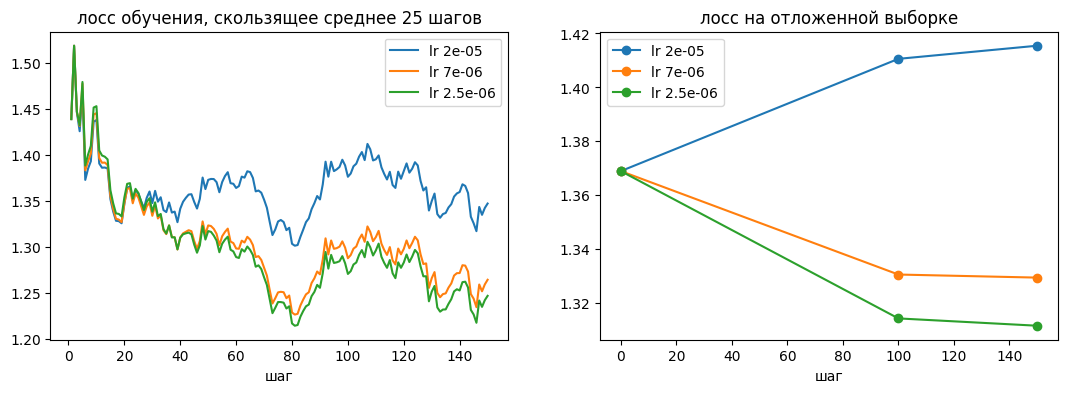

выбран lr: 2.5e-06


In [6]:
chk = json.load(open(RES / "finetune_lr.json"))
display(pd.DataFrame(chk["rows"]).assign(lr=lambda d: d.lr.map("{:g}".format)).round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r in chk["rows"]:
    name = f"finetune_check_lr{r['lr']:g}"
    st, ev = jl(name, "steps.jsonl"), jl(name, "eval.jsonl")
    ax[0].plot(st.step, st.loss.rolling(25, min_periods=1).mean(), label=f"lr {r['lr']:g}")
    ax[1].plot(ev.step, ev.eval_loss, "o-", label=f"lr {r['lr']:g}")
ax[0].set_title("лосс обучения, скользящее среднее 25 шагов"); ax[1].set_title("лосс на отложенной выборке")
for a in ax:
    a.set_xlabel("шаг"); a.legend()
plt.show()
print("выбран lr:", chk["chosen_lr"] if chk["chosen_lr"] is not None else "нет, полный прогон не запускать")

In [7]:
!cd $HW2 && $PY -m cce_repro.run finetune

===== finetune =====
   lr = 2.5e-06 (выбран проверкой)
нет results/cce_config.json: форма b64_v64_w4, выбранная в ноутбуке 1
   cce seed=0
   cce seed=0 step=50 loss=1.4787
   cce seed=0 step=100 loss=1.3444
   cce seed=0 step=150 loss=1.3713
   cce seed=0 step=200 loss=1.2555
   cce seed=0 step=250 loss=1.1058
   cce seed=0 step=300 loss=1.2437
   cce seed=0 step=350 loss=1.0668
   cce seed=0 step=400 loss=1.2957
   cce seed=0 step=450 loss=1.0534
   cce seed=0 step=500 loss=1.0237
   torch_compile seed=0
   torch_compile seed=0 step=50 loss=1.4788
   torch_compile seed=0 step=100 loss=1.3443
   torch_compile seed=0 step=150 loss=1.3713
   torch_compile seed=0 step=200 loss=1.2551
   torch_compile seed=0 step=250 loss=1.1054
   torch_compile seed=0 step=300 loss=1.2442
   torch_compile seed=0 step=350 loss=1.0666
   torch_compile seed=0 step=400 loss=1.2956
   torch_compile seed=0 step=450 loss=1.0533
   torch_compile seed=0 step=500 loss=1.0243
   cce seed=1
   cce seed=1 step=50 lo

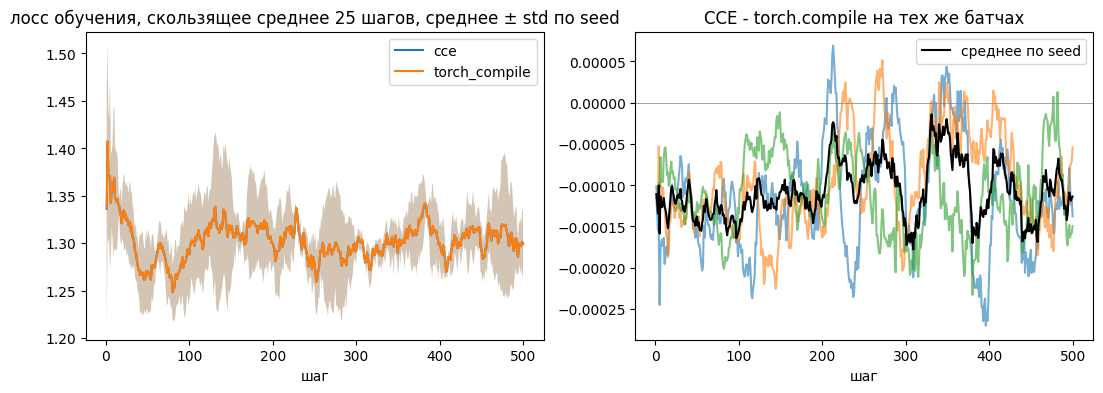

method,cce,torch_compile
seed,,
0,1.2842,1.2844
1,1.3020,1.3021
2,1.3210,1.3211


последние 100 шагов: |CCE - torch.compile| = 0.0001, разброс между seed (std) = 0.0184, критерий выполнен


mean                   std              
method     cce torch_compile     cce torch_compile
step                                              
0       1.3689        1.3689  0.0000        0.0000
100     1.3135        1.3135  0.0010        0.0010
200     1.3096        1.3097  0.0006        0.0006
300     1.3065        1.3065  0.0011        0.0011
400     1.3041        1.3041  0.0008        0.0008
500     1.3031        1.3032  0.0007        0.0007

,step_s,peak_mib,skipped,tokens
method,,,,
cce,1.163,9482.310,0.003,1636.24
torch_compile,1.121,9474.243,0.003,1636.24


In [8]:
steps, ev, cfg = jl("finetune", "steps.jsonl"), jl("finetune", "eval.jsonl"), json.load(open(RES / "finetune" / "config.json"))
W, S = 25, cfg["steps"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for m, d in steps.groupby("method"):
    piv = d.pivot(index="step", columns="seed", values="loss").rolling(W, min_periods=1).mean()
    mu, sd = piv.mean(axis=1), piv.std(axis=1)
    ax[0].plot(mu.index, mu, label=m)
    ax[0].fill_between(mu.index, mu - sd, mu + sd, alpha=0.25)
ax[0].set_title(f"лосс обучения, скользящее среднее {W} шагов, среднее ± std по seed"); ax[0].set_xlabel("шаг"); ax[0].legend()
p = steps.pivot_table(index=["seed", "step"], columns="method", values="loss")
diff = (p["cce"] - p["torch_compile"]).unstack("seed").rolling(W, min_periods=1).mean()
ax[1].plot(diff.index, diff.values, alpha=0.6); ax[1].plot(diff.index, diff.mean(axis=1), "k", label="среднее по seed")
ax[1].axhline(0, color="gray", lw=0.5); ax[1].set_title("CCE - torch.compile на тех же батчах"); ax[1].set_xlabel("шаг"); ax[1].legend()
plt.show()

last = steps[steps.step > S - 100].groupby(["seed", "method"]).loss.mean().unstack("method")
display(last.round(4))
gap = abs(last["cce"].mean() - last["torch_compile"].mean())
spread = last.std().mean()
print(f"последние 100 шагов: |CCE - torch.compile| = {gap:.4f}, разброс между seed (std) = {spread:.4f}, "
      f"критерий {'выполнен' if gap < spread else 'не выполнен'}")
display(ev.pivot_table(index="step", columns="method", values="eval_loss", aggfunc=["mean", "std"]).round(4))
display(steps[steps.step > 5].groupby("method").agg(step_s=("step_s", "mean"), peak_mib=("peak_mib", "max"),
                                                       skipped=("skipped", "mean"), tokens=("tokens", "mean")).round(3))

**Сравнение со статьёй и вывод 2.1.** Статья: рисунок 4 (4 модели, 5 seed, из статьи). Воспроизведение: Qwen2.5-0.5B-Instruct, 3 seed, 500 шагов, lr 2.5e-6, T4.

| | статья | T4 |
|---|---|---|
| кривые лосса CCE и torch.compile | «indistinguishable» (из статьи) | на тех же батчах средняя разница CCE - torch.compile -0.00011 (0.02% от лосса), максимум по 3 000 шагов 0.0014 |
| последние 100 шагов, среднее по seed | - | 1.3024 против 1.3025: разница 0.0001 при разбросе между seed 0.018 |
| лосс на отложенной выборке | - | 1.3689 на шаге 0, 1.3031 против 1.3032 на шаге 500; по всем seed и шагам разница не больше 7e-5 |
| время шага, батч 8 | - | CCE 1.163 s, torch.compile 1.121 s: CCE на 3.7% медленнее |
| пик памяти, батч 8 | - | 9 450 и 9 449 MiB (при 8 последовательностях логиты пик не определяют) |

Парное сравнение посчитано по `finetune/steps.jsonl` (расчёт).

1. Проверка lr: выбран 2.5e-6, а не 2e-5, как в [`training/train.py`](https://github.com/apple-aiml-research/ml-cross-entropy/blob/main/training/train.py): у авторов батч 64, в воспроизведении 8. С lr 2e-5 лосс на отложенной выборке за 150 шагов растёт (1.369 -> 1.415), с 2e-5 · 8 / 64 = 2.5e-6 падает (-> 1.312). Lr выбран правилом, зафиксированным до прогона, по torch.compile, до запуска CCE.
2. Модель учится. Лосс на отложенной выборке монотонно падает с 1.369 до 1.303. Лосс обучения по блокам по 100 шагов почти постоянен (1.29-1.31). Основное снижение приходится на первые ~50 шагов (в проверке с тем же lr 1.338 на шагах 1-50 и 1.255 на шагах 51-100), дальше его перекрывает разница между батчами.
3. Сравнение методов: критерий (разница средних лоссов на последних 100 шагах меньше разброса между seed) выполнен с запасом в 150 раз.
   - Знак разницы. На тех же батчах у CCE лосс обучения ниже на 1e-4 при всех трёх seed (95%-интервал ±1.5e-5). На отложенной выборке, где лосс обоих методов считается одинаково в fp32, разница в среднем 2.4e-5, то есть в 4 раза меньше. Значит, основная часть сдвига в том, как каждый метод считает сам лосс в fp16, а не в траектории обучения.
   - Предыдущие прогоны. В прогоне с 8-bit AdamW и постоянным lr 2e-5 лосс рос, но CCE и torch.compile совпадали так же (разница 0.0001 при разбросе 0.021; журналы этого прогона в репозиторий не входят). Совпадение методов от настроек обучения не зависит.
4. Цена CCE: шаг 1.163 s против 1.121 s у torch.compile (на 3.7% медленнее); пик памяти одинаковый (9 450 и 9 449 MiB).

Вывод: утверждение статьи воспроизводится. Кривые CCE и torch.compile неразличимы: разница в 150 раз меньше разброса между seed и составляет 0.02% лосса. Фильтрация градиента сходимости не мешает. Цена на T4: шаг обучения длиннее на 3.7%, хотя сам слой лосса медленнее в 1.76 раза (ноутбук 1). В статье замедление обучения из-за CCE оценено в 1-2% для модели, где слой лосса медленнее torch.compile примерно на 50% (Phi 3.5 Mini, приложение C.2, из статьи).

## 2.2 Максимальный батч (рисунок 1, таблица A4)

**Статья.** «Our Cut Cross-Entropy (CCE) enables increasing the batch size by 1.5x (Llama 2 13B) to 10x (GPT 2, Gemma 2 2B), with no sacrifice in speed or convergence.» (подпись к рисунку 1). Таблица A4 считается по формуле приложения D (16 GPU по 80 ГБ, 65 536 токенов, bf16, checkpointing), а не замеряется; для Gemma (2B) 14.9x, Gemma 2 (2B) 9.5x.

**Что делается.** 
1. Максимальный батч: полный шаг обучения с checkpointing, последовательности по 512 токенов, все токены в лоссе; для стандартного лосса transformers (`hf`), `torch_compile` и CCE, каждый в отдельном процессе. Критерий: кратный рост батча с CCE.
2. Пропускная способность на найденном максимуме или, если повторные шаги на нём не помещаются, на батче до 20% меньше.
3. Формула приложения D: наклон пика памяти по числу токенов сравнивается с членами формулы; формула применяется к Qwen2.5-0.5B в постановке статьи (расчёт) и проверяется на строке Gemma 2 (2B). Критерий: формула согласуется с замером.

Отличия от рисунка 1: одна T4 вместо 16 x 80 ГБ, 8-bit AdamW (состояния 942 MiB вместо 3 769 MiB в fp32, расчёт; под батч остаётся больше памяти), fp32-веса, поэтому чекпоинты активаций в fp32 (в формуле bf16, 2 Б).

In [9]:
!cd $HW2 && $PY -m cce_repro.run max_batch

===== max_batch =====
   max batch: hf
   hf: max_batch=9 (поиск 10), peak=13597.7353515625 MiB
   max batch: torch_compile
   torch_compile: max_batch=29 (поиск 29), peak=13054.2314453125 MiB
   max batch: cce
   cce: max_batch=109 (поиск 109), peak=12729.70166015625 MiB
===== max_batch: done


In [10]:
mb = jl("max_batch").set_index("impl")
display(mb[["max_batch", "max_tokens", "max_batch_search", "first_oom_batch", "recheck_ok", "peak_at_max_mib", "static_mib",
            "timed_batch", "step_s_at_timed", "tokens_per_s"]].round(1))
rows = {}
for impl, r in mb.iterrows():
    pk = {int(k): v for k, v in r.peaks_by_bs.items() if v is not None and int(k) >= 4}
    x = np.array(sorted(pk)) * 512
    rows[impl] = np.polyfit(x, [pk[k] for k in sorted(pk)], 1)[0]
r0 = mb.iloc[0]
MiB = 2**20
form = {"логиты fp32, V x 4 Б": r0.vocab * 4 / MiB,
        "активации checkpointing, L x D x 2 Б": r0.layers * r0.hidden * 2 / MiB,
        "активации checkpointing, L x D x 4 Б": r0.layers * r0.hidden * 4 / MiB}
display(pd.Series(rows, name="замер: MiB на токен (наклон пика)").to_frame().round(4))
display(pd.Series(form, name="формула: MiB на токен (расчёт)").to_frame().round(4))
print("рост батча (замер):", {k: round(float(mb.max_batch[k] / mb.max_batch["hf"]), 2) for k in mb.index})
print(json.dumps(json.load(open(RES / "max_batch" / "formula.json")), indent=1, ensure_ascii=False))

,max_batch,max_tokens,max_batch_search,first_oom_batch,recheck_ok,peak_at_max_mib,static_mib,timed_batch,step_s_at_timed,tokens_per_s
impl,,,,,,,,,,
hf,9,4608,10,11,True,13597.7,1901.7,9,1.5,3088.2
torch_compile,29,14848,29,30,True,13054.2,1901.7,29,4.5,3302.0
cce,109,55808,109,110,True,12729.7,1901.5,94,17.1,2810.3


,замер: MiB на токен (наклон пика)
hf,2.1225
torch_compile,0.7235
cce,0.1618


,формула: MiB на токен (расчёт)
"логиты fp32, V x 4 Б",0.5796
"активации checkpointing, L x D x 2 Б",0.0410
"активации checkpointing, L x D x 4 Б",0.0820


рост батча (замер): {'hf': 1.0, 'torch_compile': 3.22, 'cce': 12.11}
{
 "Qwen2.5-0.5B-Instruct": {
  "logits_mib": 37984.0,
  "activations_mib": 2688.0,
  "weights_opt_grad_mib": 3769.1708984375,
  "max_tokens_before": 1973928.51140834,
  "max_tokens_after": 29867418.30952381,
  "increase": 15.130952380952381
 },
 "Gemma 2 (2B), проверка": {
  "logits_mib": 64000.0,
  "activations_mib": 7488.0,
  "weights_opt_grad_mib": 19946.0,
  "max_tokens_before": 1108206.3527305282,
  "max_tokens_after": 10580055.521367522,
  "increase": 9.547008547008547
 }
}


**Сравнение со статьёй и вывод 2.2.**

| | статья (из статьи) | T4 |
|---|---|---|
| рост батча с CCE | 1.5x-10x (подпись к рисунку 1); в таблице A4 Gemma (2B) 14.9x, Gemma 2 (2B) 9.5x, расчёт по приложению D | замер на T4: 9 -> 109 последовательностей по 512 токенов, 12.1x; torch.compile 29, 3.2x |
| формула приложения D для Qwen2.5-0.5B в постановке статьи (16 x 80 ГБ, 65 536 токенов) | - | 15.1x (расчёт) |
| проверка формулы на Gemma 2 (2B) | 1 108 206 -> 10 580 057 токенов | 1 108 206 -> 10 580 056 (расчёт) |
| «with no sacrifice in speed» | - | пропускная способность: hf 3 088 токен/с (батч 9), torch.compile 3 302 (батч 29), CCE 2 810 (батч 94) |

1. Максимальный батч: hf 9, torch.compile 29, CCE 109 последовательностей; критерий кратного роста выполнен (12.1x).
   - Предел батча. Батч упирается не только в выделенную память. На максимуме пик 12 730-13 598 MiB из 14 912 MiB, а следующий батч падает из-за фрагментации: у hf поиск нашёл 10, а перепроверка прошла только на 9.
   - Повторяемость. Первый прогон на Kaggle дал те же максимальные батчи: 9, 29 и 109.
2. Пропускная способность: на максимальном батче CCE обрабатывает на 9% меньше токенов в секунду, чем hf, и на 15% меньше, чем torch.compile. Скорость CCE измерена на батче 94: на 109 повторные шаги не поместились. Это следствие отставания ядер CCE на T4 (ноутбук 1, раздел 1.2).
3. Формула приложения D: на строке Gemma 2 (2B) расчёт совпадает с таблицей A4 до одного токена. Критерий согласия с замером выполнен частично. Формула даёт 15.1x против замеренных 12.1x, то есть сходится по порядку величины. Но её члены на токен отличаются от замера в 2-3.7 раза, и отличия частично компенсируют друг друга. Память на токен, наклон пика по батчу (замер) против членов формулы (расчёт):
   - **hf: 2.12 MiB.** Это в 3.7 раза больше 0.58 MiB логитов в fp32, которые учитывает формула. По-видимому, transformers держит одновременно логиты в fp16, их fp32-копию для лосса, промежуточный результат softmax и градиент; по отдельности это не измерялось. Статья сама пишет, что формула «likely undercounts».
   - **torch.compile: 0.72 MiB**, около 1.25 размера логитов в fp32.
   - **CCE: 0.16 MiB.** Логитов нет, остаются чекпоинты активаций (0.08 MiB в fp32: в воспроизведении fp32-веса, в формуле 0.04 MiB в bf16) и прочие буферы на токен.

Вывод: экономия памяти даёт кратный рост батча и на одной T4: 12.1x по последовательностям против 3.2x у torch.compile. Это внутри диапазона таблицы A4, а формула приложения D для этой модели предсказывает 15.1x. Утверждение «без потери скорости» на T4 воспроизводится частично: пропускная способность на максимальном батче ниже на 9-15%.

## Сохранение результатов

In [ ]:
!cd $HW2 && $PY -m cce_repro.run zip=results_training
z = RES.parent / "results_training.zip"
try:
    from google.colab import files
    files.download(str(z))
except (ImportError, NotImplementedError):
    print("Kaggle: файл в", z)